In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp, quad

sig = lambda th: 1 / (1 + np.exp(-th))
eta, n = 0.02, 400_000

# (a) expected points: rows = shoot 2, shoot 3; columns = guard paint, guard arc
make = np.array([[0.40, 0.60], [0.40, 0.25]])
print("expected points:\n", np.array([[2], [3]]) * make)
xs, ys = 0.40 / 0.85, 0.45 / 0.85                   # from the two indifference equations
print(f"x* = {xs:.4f}  y* = {ys:.4f}  value = {0.8 + 0.4 * xs:.4f}")

# (c)(i) mean-flow orbit from (0.2, 0.3), and the conserved quantity K
def K(x, y):
    f = lambda s, c: (s - c) / (s * (1 - s)) ** 2
    return quad(f, xs, x, args=(xs,))[0] + quad(f, ys, y, args=(ys,))[0]

def mean_flow(t, th):
    x, y = sig(th[0]), sig(th[1])
    return [eta * x * (1 - x) * 0.85 * (y - ys), -eta * y * (1 - y) * 0.85 * (x - xs)]

lap = 8000                                          # one lap is about 7,900 possessions
sol = solve_ivp(mean_flow, [0, lap], [np.log(0.2 / 0.8), np.log(0.3 / 0.7)],
                t_eval=np.linspace(0, lap, 300), rtol=1e-10, atol=1e-12)
xo, yo = sig(sol.y[0]), sig(sol.y[1])
Ko = np.array([K(a, b) for a, b in zip(xo, yo)])
print(f"\nmean flow (one lap): x in [{xo.min():.4f}, {xo.max():.4f}], y in [{yo.min():.4f}, {yo.max():.4f}]")
print(f"K = {Ko[0]:.5f}, largest relative change = {abs(Ko - Ko[0]).max() / Ko[0]:.1e}")

#  noisy learners
def run(tau):
    u = np.random.default_rng(2026).random((n, 3))
    th1, th2, b1, b2 = 0.3, -0.3, 0.0, 0.0          # logits and baselines
    X, Y = np.zeros(n), np.zeros(n)
    for t in range(n):
        x, y = sig(th1), sig(th2)
        X[t], Y[t] = x, y
        a1 = int(u[t, 0] < x)                        # 1 = offense shoots a 3
        a2 = int(u[t, 1] < y)                        # 1 = defense guards the paint
        pts = (2 + a1) * int(u[t, 2] < make[a1, 1 - a2])
        th1 += eta * ((pts - b1) * (a1 - x) - tau * th1 * x * (1 - x))
        th2 += eta * ((-pts - b2) * (a2 - y) - tau * th2 * y * (1 - y))
        b1 += (pts - b1) / (t + 1)                   # average of all rewards so far
        b2 += (-pts - b2) / (t + 1)
    return X, Y


expected points:
 [[0.8  1.2 ]
 [1.2  0.75]]
x* = 0.4706  y* = 0.5294  value = 0.9882

mean flow (one lap): x in [0.1628, 0.8082], y in [0.1918, 0.8372]
K = 1.43383, largest relative change = 2.2e-10



tau = 0: last-quarter average (x, y) = (0.3868, 0.4570)
 mean distance from (x*, y*): early = 0.5125, late = 0.6755

tau = 0.05: last-quarter average (x, y) = (0.4696, 0.5226)
 mean distance from (x*, y*): early = 0.1745, late = 0.1883


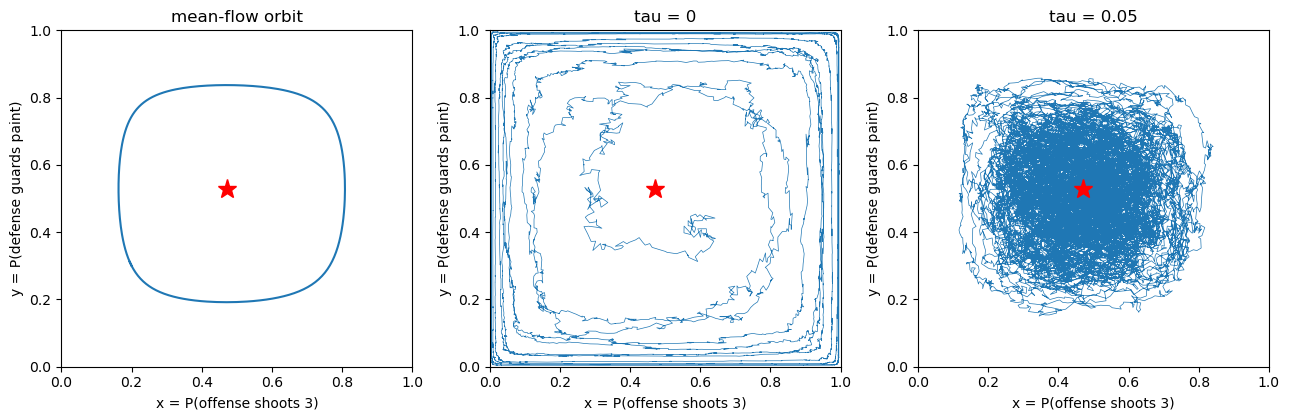

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(13, 4.3))
ax[0].plot(xo, yo)
ax[0].set_title("mean-flow orbit")
q = n // 4
for a, tau in zip(ax[1:], (0, 0.05)):
    X, Y = run(tau)
    d = np.hypot(X - xs, Y - ys)
    print(f"\ntau = {tau}: last-quarter average (x, y) = ({X[-q:].mean():.4f}, {Y[-q:].mean():.4f})")
    print(f" mean distance from (x*, y*): early = {d[:q].mean():.4f}, late = {d[-q:].mean():.4f}")
    a.plot(X[::20], Y[::20], lw=0.5)
    a.set_title(f"tau = {tau}")
for a in ax:
    a.plot(xs, ys, "r*", ms=14)                       # equilibrium
    a.set_xlim(0, 1); a.set_ylim(0, 1)
    a.set_xlabel("x = P(offense shoots 3)"); a.set_ylabel("y = P(defense guards paint)")
plt.tight_layout()